# Fase A — Análisis Exploratorio (EDA)
**Proyecto 2 y 3 · Introducción a la ciencia de los datos**

**Dataset:** MEN — Estadísticas en educación preescolar, básica y media por municipio (2011–2024), el mismo del Proyecto 1.

**Pregunta de negocio:** *¿Qué características de un municipio (cobertura, reprobación, repitencia, tamaño, región) permiten anticipar si tendrá una **deserción escolar alta** (> 5 %), para que el Ministerio y las Secretarías de Educación focalicen sus programas de permanencia?*

**Variable objetivo:** `DESERCIÓN` (% de estudiantes que abandonan el sistema durante el año). Para clasificación se deriva `ALTO_RIESGO_DESERCION = DESERCIÓN > 5 %`.

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
os.makedirs("figuras", exist_ok=True)

def guardar(nombre):
    plt.savefig(f"figuras/{nombre}.png", dpi=130, bbox_inches="tight")

RUTA = os.environ.get("DATA_PATH") or glob.glob("../MEN_ESTADISTICAS*.csv")[0]
raw = pd.read_csv(RUTA, dtype=str)  # todo como texto: los % vienen como "56,11%"
print(raw.shape)
raw.head()

(15707, 41)


,AÑO,CÓDIGO_MUNICIPIO,MUNICIPIO,CÓDIGO_DEPARTAMENTO,DEPARTAMENTO,CÓDIGO_ETC,ETC,POBLACIÓN_5_16,TASA_MATRICULACIÓN_5_16,COBERTURA_NETA,...,REPROBACIÓN,REPROBACIÓN_TRANSICIÓN,REPROBACIÓN_PRIMARIA,REPROBACIÓN_SECUNDARIA,REPROBACIÓN_MEDIA,REPITENCIA,REPITENCIA_TRANSICIÓN,REPITENCIA_PRIMARIA,REPITENCIA_SECUNDARIA,REPITENCIA_MEDIA
0,2024,05004,Abriaquí,05,Antioquia,3758,Antioquia (ETC),499,"56,11%","56,11%",...,"0,32%",0%,0%,0%,"2,33%","8,41%",0%,"8,51%",13%,"2,33%"
1,2024,15204,Cómbita,15,Boyacá,3769,Boyacá (ETC),1862,"95,33%","95,33%",...,"2,62%",0%,"1,71%","4,4%","1,05%","7,94%","1,69%","4,94%","14,53%",0%
2,2024,99773,Cumaribo,99,Vichada,3832,Vichada (ETC),25239,"50,7%","50,7%",...,"15,22%",0%,"20,39%","8,09%","5,7%","20,14%","0,63%","26,99%","11,05%","4,34%"
3,2024,99624,Santa Rosalía,99,Vichada,3832,Vichada (ETC),1157,"81,42%","81,42%",...,"7,63%",0%,"7,12%","10,92%","5,43%","13,17%",0%,15%,"16,67%","2,17%"
4,2024,99524,La Primavera,99,Vichada,3832,Vichada (ETC),2645,"90,96%","90,96%",...,"8,83%",0%,11%,"8,84%","2,91%","13,15%","0,68%","17,38%","11,67%","3,64%"


## 1. Estructura y tipos
Todas las métricas llegan como texto con `%` y coma decimal, por eso se leen como `str` y se convierten. Para el EDA solo se hace la conversión mínima (texto → número) y se excluye la fila agregada `NACIONAL`; la limpieza completa está en la Fase B.

In [2]:
ID_COLS = ["AÑO", "CÓDIGO_MUNICIPIO", "MUNICIPIO", "CÓDIGO_DEPARTAMENTO", "DEPARTAMENTO", "CÓDIGO_ETC", "ETC"]
NUM_COLS = [c for c in raw.columns if c not in ID_COLS]

df = raw[raw["DEPARTAMENTO"] != "NACIONAL"].copy()
# POBLACIÓN de 2021 trae separador de miles ("1.148" = 1148, "3.89" = 3890); detalle en la Fase B
partes = df["POBLACIÓN_5_16"].str.replace(",", ".", regex=False).str.split(".")
df["POBLACIÓN_5_16"] = partes.map(lambda p: p[0] + "".join(x.ljust(3, "0") for x in p[1:]), na_action="ignore")
for c in NUM_COLS:
    df[c] = pd.to_numeric(df[c].str.replace("%", "").str.replace(",", "."), errors="coerce")
df["AÑO"] = df["AÑO"].astype(int)
print(df.dtypes.value_counts())
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]} | Años: {df['AÑO'].min()}–{df['AÑO'].max()} | Municipios únicos: {df['CÓDIGO_MUNICIPIO'].str.zfill(5).nunique()}")

float64    34
str         6
int64       1
Name: count, dtype: int64
Filas: 15,704 | Columnas: 41 | Años: 2011–2024 | Municipios únicos: 1123


In [3]:
clasificacion = pd.DataFrame({
    "variable": ["MUNICIPIO, DEPARTAMENTO, ETC, códigos", "AÑO", "POBLACIÓN_5_16", "TASA_MATRICULACIÓN, COBERTURA_*, DESERCIÓN_*, APROBACIÓN_*, REPROBACIÓN_*, REPITENCIA_*", "TAMAÑO_PROMEDIO_DE_GRUPO", "SEDES_CONECTADAS_A_INTERNET"],
    "tipo": ["Categórica nominal", "Numérica discreta (temporal)", "Numérica discreta (conteo)", "Numérica continua (tasa %)", "Numérica continua", "Numérica continua (%)"],
})
clasificacion

,variable,tipo
0,"MUNICIPIO, DEPARTAMENTO, ETC, códigos",Categórica nominal
1,AÑO,Numérica discreta (temporal)
2,POBLACIÓN_5_16,Numérica discreta (conteo)
3,"TASA_MATRICULACIÓN, COBERTURA_*, DESERCIÓN_*, ...",Numérica continua (tasa %)
4,TAMAÑO_PROMEDIO_DE_GRUPO,Numérica continua
5,SEDES_CONECTADAS_A_INTERNET,Numérica continua (%)


In [4]:
desc = df[NUM_COLS].describe().T
desc["IQR"] = desc["75%"] - desc["25%"]
desc["nulos_%"] = (df[NUM_COLS].isna().mean() * 100).round(1)
desc[["mean", "std", "min", "25%", "50%", "75%", "max", "IQR", "nulos_%"]].round(2)

,mean,std,min,25%,50%,75%,max,IQR,nulos_%
POBLACIÓN_5_16,8840.64,45570.44,1.0,1426.25,2966.00,6273.50,1479334.00,4847.25,0.0
TASA_MATRICULACIÓN_5_16,84.71,18.39,0.0,74.59,85.03,95.01,279.03,20.42,0.7
COBERTURA_NETA,85.24,16.84,0.0,76.43,86.05,94.27,264.54,17.84,0.7
COBERTURA_NETA_TRANSICIÓN,57.56,16.08,0.0,47.41,57.68,67.79,150.47,20.38,0.3
COBERTURA_NETA_PRIMARIA,82.27,17.08,0.0,72.90,82.50,91.60,254.96,18.70,0.6
COBERTURA_NETA_SECUNDARIA,69.86,18.68,0.0,60.38,70.80,80.40,229.44,20.02,0.6
COBERTURA_NETA_MEDIA,41.00,15.61,0.0,31.41,41.40,50.70,170.26,19.29,0.6
COBERTURA_BRUTA,97.04,21.14,0.0,85.08,96.96,108.61,286.92,23.53,0.4
COBERTURA_BRUTA_TRANSICIÓN,86.70,25.26,0.0,71.17,84.75,99.38,259.29,28.21,0.6
COBERTURA_BRUTA_PRIMARIA,104.29,25.06,0.0,89.03,102.48,116.75,326.40,27.72,0.5


**Lectura de la tabla:** `TAMAÑO_PROMEDIO_DE_GRUPO` y `SEDES_CONECTADAS_A_INTERNET` tienen ~50 % de nulos (solo se reportan 2011–2017). Varias coberturas superan el 100 %, lo que es posible en la metodología del MEN (la cobertura bruta incluye estudiantes en extraedad y las proyecciones de población del DANE no siempre coinciden con la matrícula real).

## 2. Histogramas de las variables numéricas principales

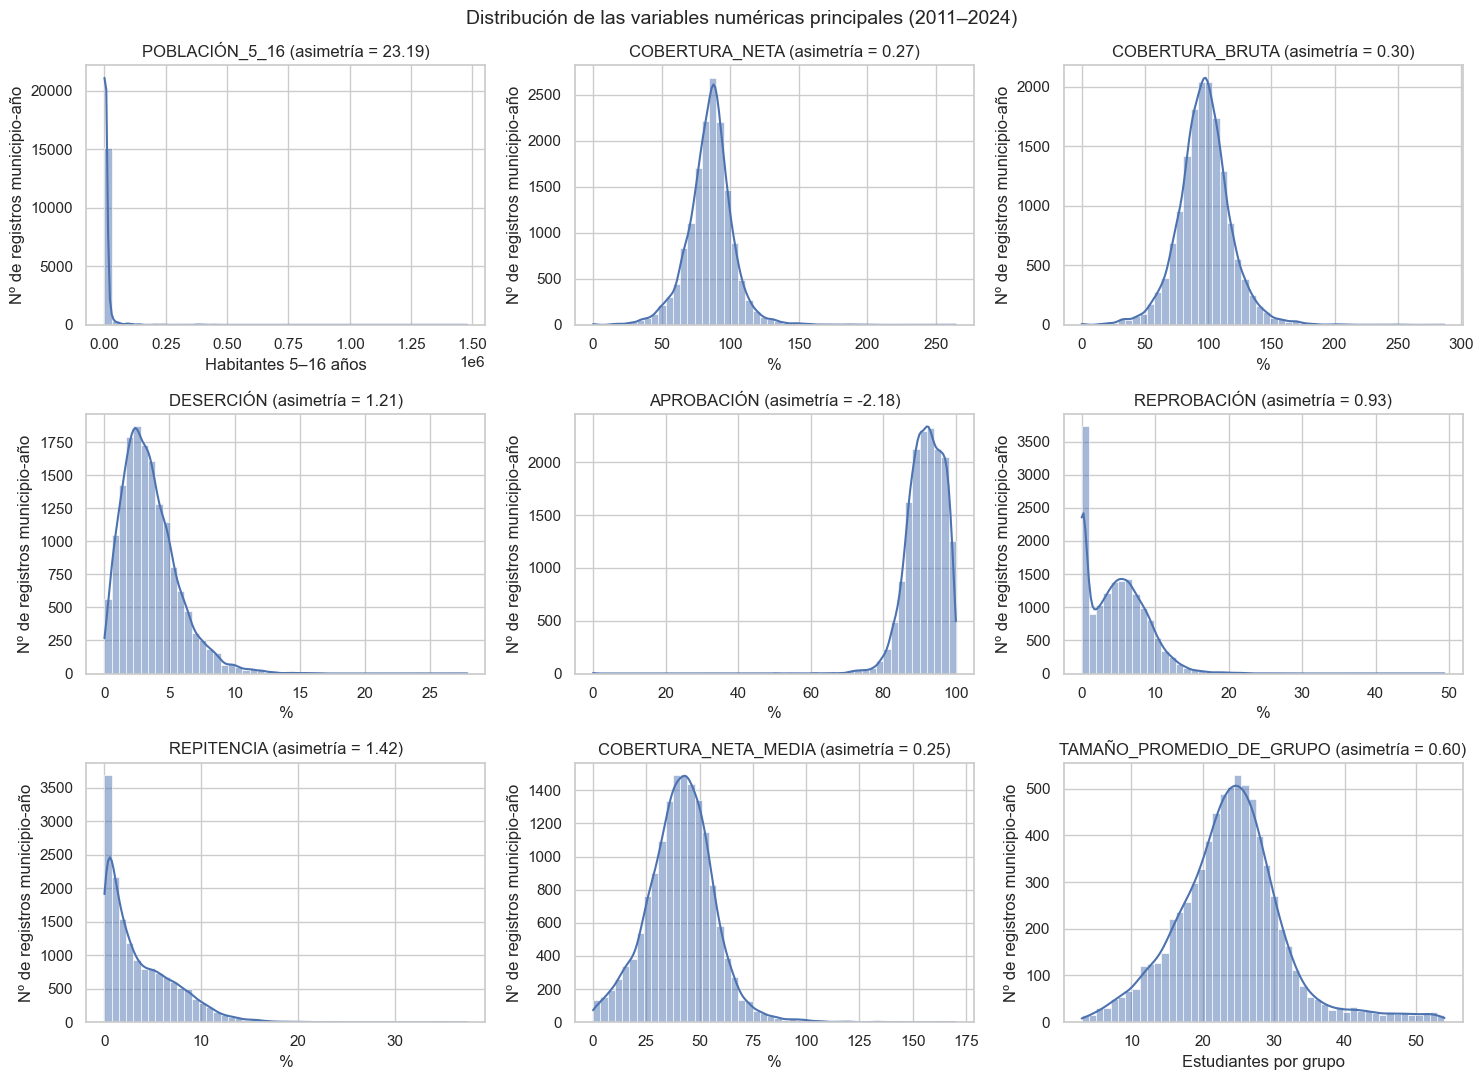

In [5]:
PRINCIPALES = ["POBLACIÓN_5_16", "COBERTURA_NETA", "COBERTURA_BRUTA", "DESERCIÓN", "APROBACIÓN", "REPROBACIÓN", "REPITENCIA", "COBERTURA_NETA_MEDIA", "TAMAÑO_PROMEDIO_DE_GRUPO"]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), PRINCIPALES):
    sns.histplot(df[c].dropna(), bins=50, kde=True, ax=ax)
    ax.set_title(f"{c} (asimetría = {df[c].skew():.2f})")
    ax.set_xlabel("Habitantes 5–16 años" if c == "POBLACIÓN_5_16" else ("Estudiantes por grupo" if c.startswith("TAMAÑO") else "%"))
    ax.set_ylabel("Nº de registros municipio-año")
fig.suptitle("Distribución de las variables numéricas principales (2011–2024)", fontsize=14)
plt.tight_layout(); guardar("a_histogramas"); plt.show()

**Insight:** La población de 5–16 años es extremadamente asimétrica (unos pocos municipios grandes como Bogotá, Medellín y Cali frente a cientos de municipios con menos de 3.000 niños), por lo que necesitará transformación logarítmica. Las coberturas se concentran alrededor de 85 % pero con una cola por encima del 100 %, mientras deserción, reprobación y repitencia son asimétricas a la derecha: la mayoría de municipios está bien y una minoría concentra los problemas. `TAMAÑO_PROMEDIO_DE_GRUPO` solo existe para 2011–2017, así que no podrá usarse como predictor.

### 2.1 Variable objetivo: deserción

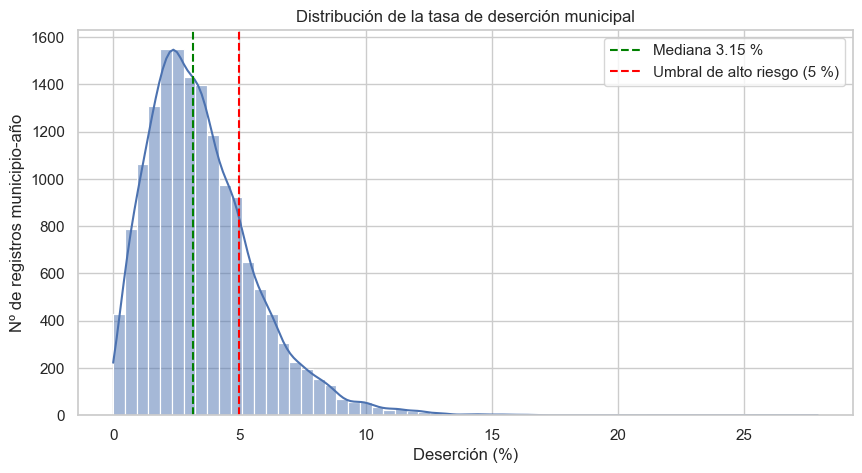

Asimetría: 1.21 | Curtosis: 3.10 | % registros > 5 %: 20.1%


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df["DESERCIÓN"].dropna(), bins=60, kde=True, ax=ax)
ax.axvline(df["DESERCIÓN"].median(), color="green", ls="--", label=f"Mediana {df['DESERCIÓN'].median():.2f} %")
ax.axvline(5, color="red", ls="--", label="Umbral de alto riesgo (5 %)")
ax.set_title("Distribución de la tasa de deserción municipal")
ax.set_xlabel("Deserción (%)"); ax.set_ylabel("Nº de registros municipio-año"); ax.legend()
guardar("a_target"); plt.show()
print(f"Asimetría: {df['DESERCIÓN'].skew():.2f} | Curtosis: {df['DESERCIÓN'].kurt():.2f} | % registros > 5 %: {(df['DESERCIÓN'] > 5).mean():.1%}")

**Insight:** La deserción es **asimétrica positiva** (asimetría 1.21): la mediana es 3.15 %, pero hay municipios que pierden más del 15 % de sus estudiantes en un año. El 20 % de los registros supera el umbral de 5 %, lo que define un problema de clasificación **desbalanceado (80/20)**: habrá que estratificar el split y evaluar con F1/Recall, no solo con Accuracy. Los outliers del lado derecho no son errores, son justamente los municipios que el negocio quiere detectar.

## 3. Boxplots para detectar outliers (método IQR)

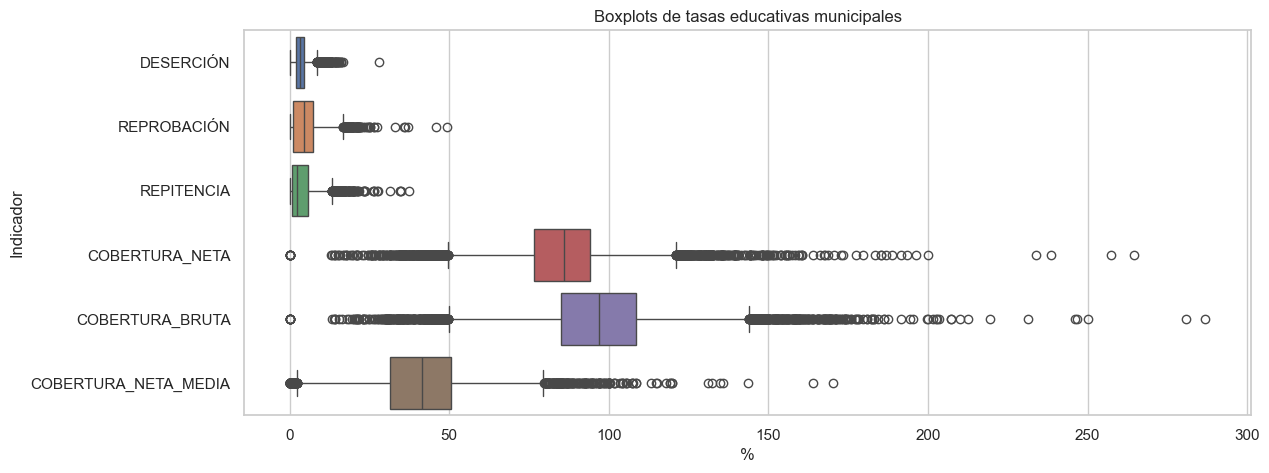

,outliers_IQR,% del total
DESERCIÓN,377,2.4%
REPROBACIÓN,99,0.6%
REPITENCIA,246,1.6%
COBERTURA_NETA,685,4.4%
COBERTURA_BRUTA,577,3.7%
COBERTURA_NETA_MEDIA,282,1.8%
POBLACIÓN_5_16,1493,9.5%


In [7]:
TASAS = ["DESERCIÓN", "REPROBACIÓN", "REPITENCIA", "COBERTURA_NETA", "COBERTURA_BRUTA", "COBERTURA_NETA_MEDIA"]
fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=df[TASAS], orient="h", ax=ax)
ax.set_title("Boxplots de tasas educativas municipales"); ax.set_xlabel("%"); ax.set_ylabel("Indicador")
guardar("a_boxplots"); plt.show()

def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.DataFrame({c: [outliers_iqr(df[c].dropna()), f"{outliers_iqr(df[c].dropna()) / df[c].notna().sum():.1%}"] for c in TASAS + ["POBLACIÓN_5_16"]},
             index=["outliers_IQR", "% del total"]).T

**Insight:** Las coberturas tienen la mayor cantidad de outliers (4–5 %), en ambos extremos: municipios con cobertura neta por debajo del 50 % (acceso precario) y otros por encima del 120 % (atraen estudiantes de municipios vecinos o tienen proyecciones de población desactualizadas). En deserción solo el 2.4 % de los registros son outliers según IQR (> 8.7 %), y se concentran en Guainía, Vaupés y otros municipios amazónicos. No se eliminarán: son datos reales y relevantes para la pregunta de negocio.

## 4. Correlaciones: Pearson y Spearman

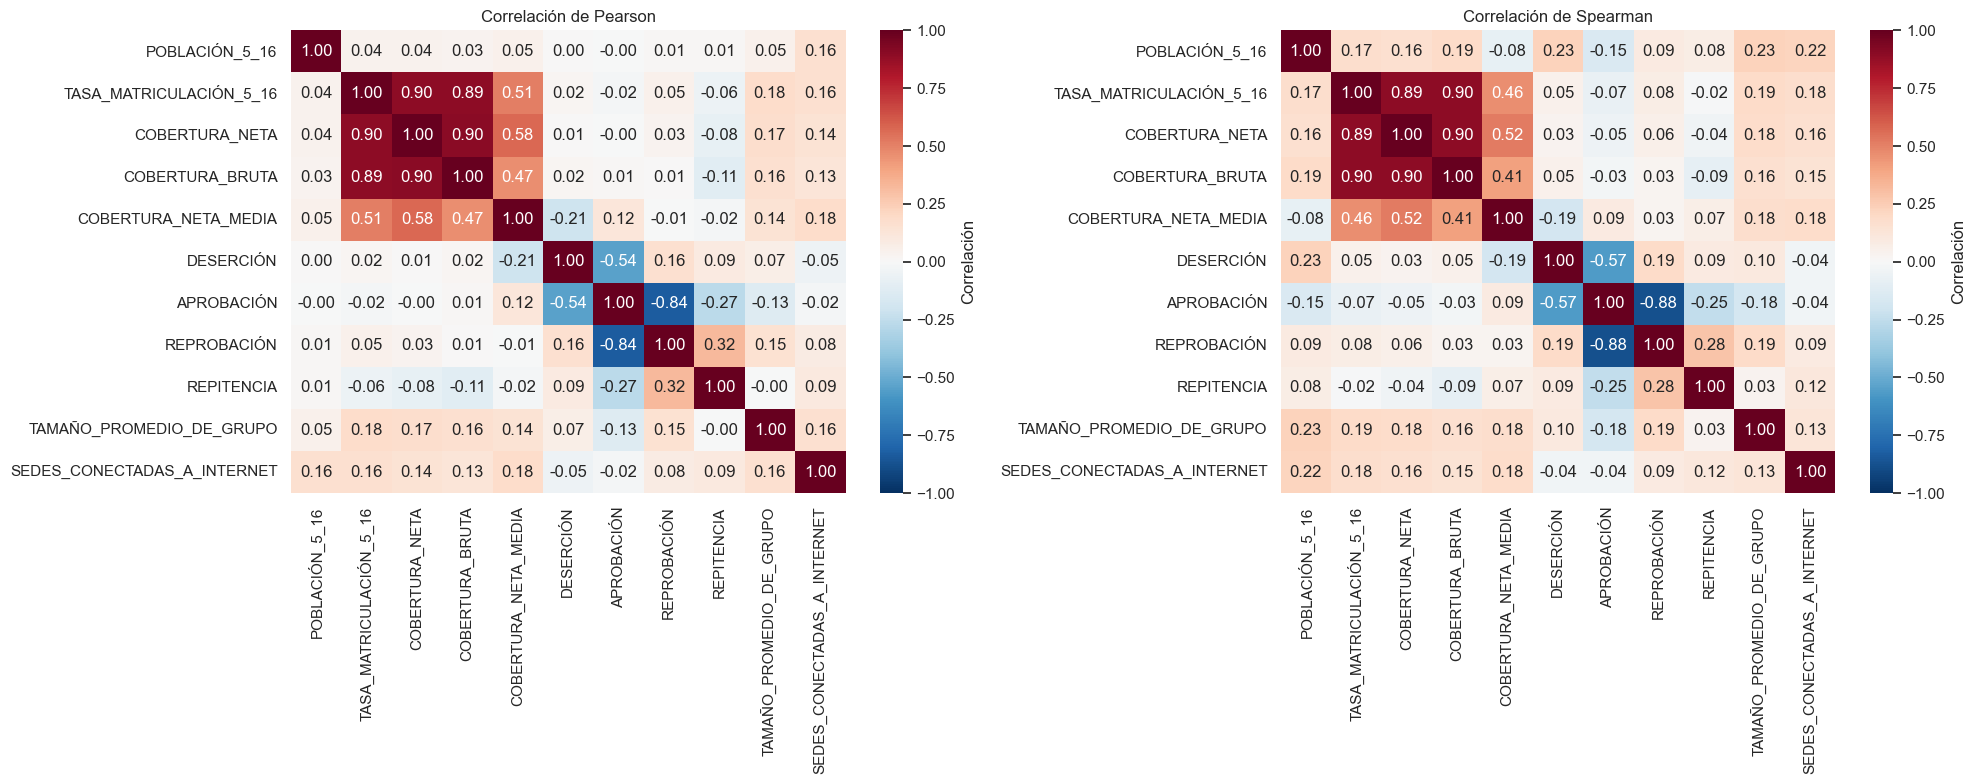

Correlación TASA_MATRICULACIÓN vs COBERTURA_NETA: 0.8959
APROBACIÓN + REPROBACIÓN + DESERCIÓN (mediana): 100.0


In [8]:
CORR_COLS = ["POBLACIÓN_5_16", "TASA_MATRICULACIÓN_5_16", "COBERTURA_NETA", "COBERTURA_BRUTA", "COBERTURA_NETA_MEDIA",
             "DESERCIÓN", "APROBACIÓN", "REPROBACIÓN", "REPITENCIA", "TAMAÑO_PROMEDIO_DE_GRUPO", "SEDES_CONECTADAS_A_INTERNET"]
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, m in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df[CORR_COLS].corr(method=m), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Correlación"})
    ax.set_title(f"Correlación de {m.capitalize()}")
plt.tight_layout(); guardar("a_correlacion"); plt.show()
print("Correlación TASA_MATRICULACIÓN vs COBERTURA_NETA:", round(df["TASA_MATRICULACIÓN_5_16"].corr(df["COBERTURA_NETA"]), 4))
print("APROBACIÓN + REPROBACIÓN + DESERCIÓN (mediana):", (df["APROBACIÓN"] + df["REPROBACIÓN"] + df["DESERCIÓN"]).median())

**Insight:** La deserción casi no se correlaciona linealmente con ninguna variable de forma individual (|r| < 0.25), salvo con la aprobación (r = −0.54). Esa relación es una **identidad contable**: aprobación + reprobación + deserción = 100 %, así que la aprobación **no puede usarse como predictor** (sería data leakage). Spearman revela algo que Pearson esconde: la población sí se relaciona con la deserción (ρ = 0.23 frente a r = 0.00), es decir, hay una relación monótona que los valores extremos de las ciudades grandes ocultan. Por eso conviene probar modelos no lineales (árboles).

## 5. Gráficos adicionales

### 5.1 Líneas: evolución de la deserción por año

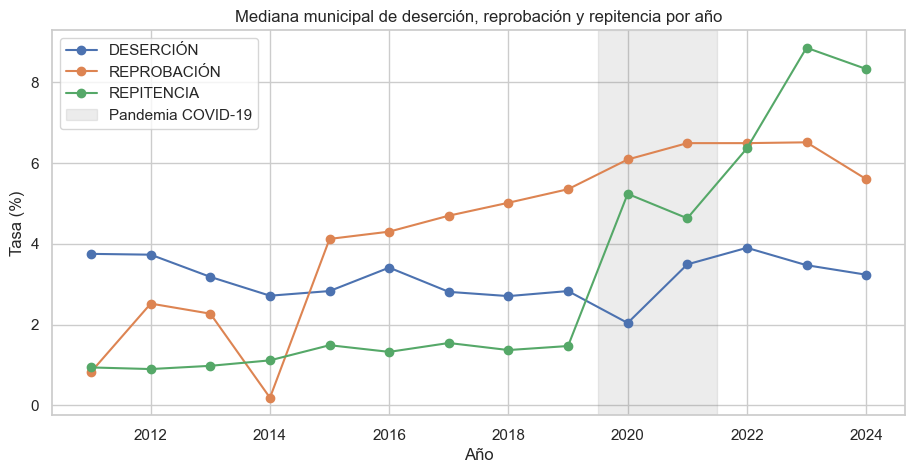

AÑO,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
DESERCIÓN,3.75,3.73,3.18,2.72,2.83,3.41,2.81,2.70,2.83,2.04,3.49,3.90,3.47,3.24
REPROBACIÓN,0.83,2.52,2.27,0.19,4.12,4.30,4.70,5.01,5.35,6.08,6.49,6.49,6.51,5.60
REPITENCIA,0.94,0.90,0.98,1.12,1.49,1.33,1.54,1.37,1.47,5.24,4.63,6.36,8.85,8.32


In [9]:
anual = df.groupby("AÑO")[["DESERCIÓN", "REPROBACIÓN", "REPITENCIA"]].median()
fig, ax = plt.subplots(figsize=(11, 5))
anual.plot(marker="o", ax=ax)
ax.axvspan(2019.5, 2021.5, color="grey", alpha=.15, label="Pandemia COVID-19")
ax.set_title("Mediana municipal de deserción, reprobación y repitencia por año")
ax.set_xlabel("Año"); ax.set_ylabel("Tasa (%)"); ax.legend()
guardar("a_lineas_anual"); plt.show()
anual.round(2).T

**Insight:** La deserción cayó a su mínimo histórico en 2020 (mediana 2.0 %) y rebotó en 2021–2022 (3.5–3.9 %), lo que es consistente con la flexibilización escolar durante la pandemia seguida del abandono posterior. La repitencia se disparó desde 2020 (de ~1.5 % a más de 8 % en 2023), lo que sugiere que la pandemia dejó rezagos de aprendizaje que siguen sin cerrarse. El año es, por tanto, una variable relevante para el modelo.

### 5.2 Barras (Pareto): deserción por departamento

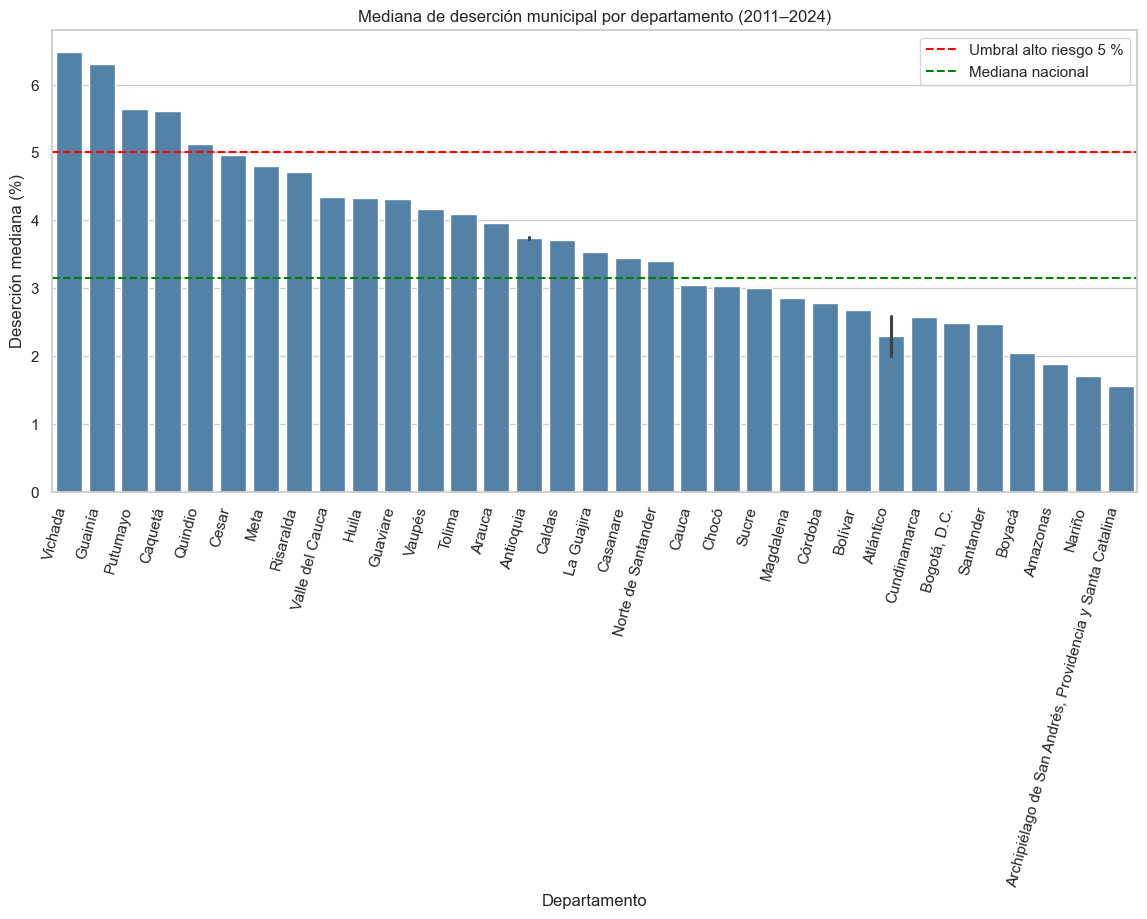

,departamento,desercion
CÓDIGO_DEPARTAMENTO,,
99,Vichada,6.48
94,Guainía,6.30
86,Putumayo,5.64
18,Caquetá,5.61
63,Quindio,5.12
20,Cesar,4.96
50,Meta,4.80
66,Risaralda,4.70


In [10]:
dep = df.groupby("CÓDIGO_DEPARTAMENTO").agg(departamento=("DEPARTAMENTO", "last"), desercion=("DESERCIÓN", "median")).sort_values("desercion", ascending=False)
fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(data=dep, x="departamento", y="desercion", color="steelblue", ax=ax)
ax.axhline(5, color="red", ls="--", label="Umbral alto riesgo 5 %")
ax.axhline(df["DESERCIÓN"].median(), color="green", ls="--", label="Mediana nacional")
ax.set_title("Mediana de deserción municipal por departamento (2011–2024)")
ax.set_xlabel("Departamento"); ax.set_ylabel("Deserción mediana (%)"); ax.legend()
plt.xticks(rotation=75, ha="right"); guardar("a_barras_departamento"); plt.show()
dep.head(8).round(2)

**Insight:** Vichada (6.5 %), Guainía (6.3 %), Putumayo y Caquetá (5.6 %) tienen medianas de deserción por encima del umbral de alto riesgo: son departamentos de la Amazonía y la Orinoquía, con población dispersa y difícil acceso. Sorprende Quindío (5.1 %), un departamento andino y urbano, en el quinto lugar: ahí el problema no parece ser la ruralidad, lo que merece análisis aparte. La región será una variable útil para el modelo.

### 5.3 Dispersión: reprobación vs. deserción

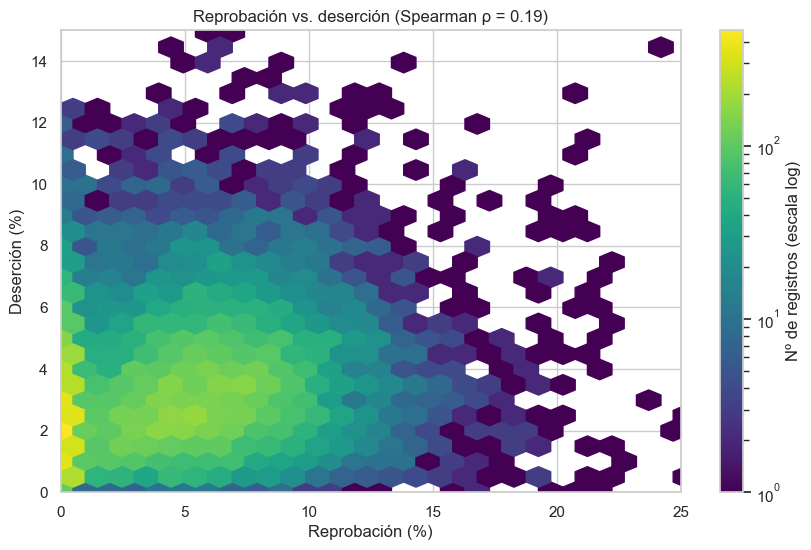

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
hb = ax.hexbin(df["REPROBACIÓN"], df["DESERCIÓN"], gridsize=50, cmap="viridis", mincnt=1, bins="log")
fig.colorbar(hb, label="Nº de registros (escala log)")
ax.set_xlim(0, 25); ax.set_ylim(0, 15)
ax.set_title(f"Reprobación vs. deserción (Spearman ρ = {df['REPROBACIÓN'].corr(df['DESERCIÓN'], method='spearman'):.2f})")
ax.set_xlabel("Reprobación (%)"); ax.set_ylabel("Deserción (%)")
guardar("a_scatter_reprobacion"); plt.show()

**Insight:** Existe una relación positiva pero débil entre reprobar y abandonar (ρ = 0.19): los municipios donde más estudiantes pierden el año tienden a tener algo más de deserción, pero hay mucha dispersión. Una sola variable no basta para identificar el riesgo; se necesita combinar varias, lo que justifica un modelo multivariado.

### 5.4 Violín: deserción según tamaño del municipio

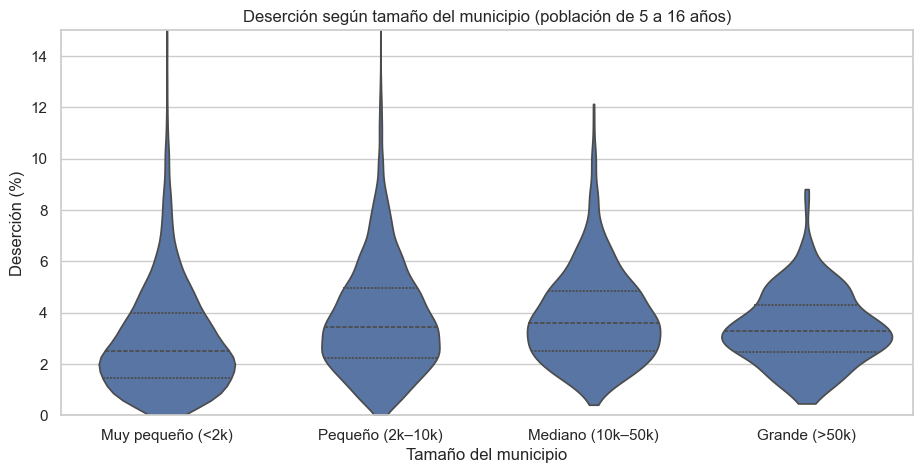

,count,50%,mean
TAMAÑO_MUNICIPIO,,,
Muy pequeño (<2k),5598.0,2.49,2.97
Pequeño (2k–10k),7766.0,3.42,3.78
Mediano (10k–50k),1821.0,3.59,3.85
Grande (>50k),377.0,3.30,3.39


In [12]:
df["TAMAÑO_MUNICIPIO"] = pd.cut(df["POBLACIÓN_5_16"], [0, 2000, 10000, 50000, np.inf],
                                labels=["Muy pequeño (<2k)", "Pequeño (2k–10k)", "Mediano (10k–50k)", "Grande (>50k)"])
fig, ax = plt.subplots(figsize=(11, 5))
sns.violinplot(data=df, x="TAMAÑO_MUNICIPIO", y="DESERCIÓN", cut=0, inner="quartile", ax=ax)
ax.set_ylim(0, 15)
ax.set_title("Deserción según tamaño del municipio (población de 5 a 16 años)")
ax.set_xlabel("Tamaño del municipio"); ax.set_ylabel("Deserción (%)")
guardar("a_violin_tamano"); plt.show()
df.groupby("TAMAÑO_MUNICIPIO", observed=True)["DESERCIÓN"].describe()[["count", "50%", "mean"]].round(2)

**Insight:** Los municipios muy pequeños (< 2.000 niños) tienen la deserción mediana más baja (2.5 %), mientras los pequeños y medianos llegan a ~3.5 %. Los grandes (> 50.000) quedan en medio (3.3 %) y con menos dispersión. La relación no es lineal (sube y luego baja), por eso se codificará como variable **ordinal** y se usarán modelos de árboles capaces de capturar este patrón.

## 6. Tres hallazgos principales (lenguaje de negocio)
1. **La deserción es un problema concentrado y geográfico.** Uno de cada cinco registros municipio-año supera el 5 % de deserción, y los casos más graves se agrupan en la Amazonía y la Orinoquía (Vichada, Guainía, Putumayo, Caquetá). Focalizar en esos territorios ataca la mayor parte del problema.
2. **La pandemia dejó una huella que aún no se cierra.** La deserción tocó un mínimo artificial en 2020 y rebotó en 2021–2022; la repitencia pasó de ~1.5 % a más de 8 %. Las estrategias de permanencia deben incluir recuperación de aprendizajes, no solo matrícula.
3. **Ninguna variable por sí sola explica la deserción.** Las correlaciones individuales son débiles (|r| < 0.25), excepto la aprobación, que es una identidad contable y no puede usarse como predictor. Para anticipar el riesgo hay que combinar cobertura, reprobación, repitencia, tamaño, región e historial del municipio en un modelo multivariado.

**Respuesta a la pregunta de reflexión:** la variable objetivo es asimétrica a la derecha, con outliers reales en el extremo alto; para el modelado eso implica (a) no eliminarlos, (b) trabajar con un objetivo binario desbalanceado y estratificado y (c) preferir métricas como F1 y Recall y modelos robustos a valores extremos.